Task 2.0 - Linear Regreesion
*Finding Closing price (Close) from a dataset of 16 features and 283,085 training examples
*Deadline - 20th Oct
-Aparajaya

In [485]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import copy,math

In [486]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
print(train.shape) 

(283085, 19)


In [487]:
#taking input from train.csv and test.csv
features = ['high','low','momentum_index','beta_indicator','risk_premium','index','volatility_factor','technical_score','oscillator_value','liquidity_ratio',
            'open','quant_index','trend_strength','market_sentiment','volume','alpha_signal']
target = 'close'
all_cols = features + [target]
train.dropna(subset=all_cols, inplace=True)
test.dropna(subset=all_cols, inplace=True)

X_train = train[features].values
y_train = train['close'].values
X_test = test[features].values
y_test = test['close'].values

print(f"Original Train shape: (283085, 19)")
print(f"Cleaned Train shape: {X_train.shape}")
print(f"Cleaned Test shape: {X_test.shape}")

Original Train shape: (283085, 19)
Cleaned Train shape: (264352, 16)
Cleaned Test shape: (173655, 16)


In [488]:
#Normalization of values
mu = X_train.mean(axis=0)   #Calculates mean for every column
sigma = X_train.std(axis=0) #Calculates standard deviation for every column
print(np.mean(X_train, axis=0))
print(np.std(X_train, axis=0))

X_train = (X_train - mu) / sigma
X_test = (X_test - mu) / sigma

my = y_train.mean(axis=0)
sigma_y = y_train.std(axis=0)
print(my)
print(sigma_y)
y_train = (y_train -my) /sigma_y

[6.57267504e+01 6.37652828e+01 6.47318736e+01 6.50049095e+01
 6.48025381e+01 1.30733305e+05 6.44389061e+01 6.47575726e+01
 6.47345748e+01 6.48094630e+01 6.46901227e+01 2.98779795e+03
 6.49259957e+01 6.47860497e+01 5.37978288e+06 6.49731503e+01]
[1.05713571e+02 1.49123209e+02 1.39798991e+02 1.02365931e+02
 1.28967192e+02 7.58861914e+04 1.59641936e+02 1.10936462e+02
 1.09494916e+02 9.81191290e+01 1.39901205e+02 1.16311949e+03
 1.13171859e+02 1.49723871e+02 1.24532311e+07 9.51936136e+01]
64.76955307280308
75.36282744650717


In [489]:
def r_squared(y_true, y_pred):
    #Calculates the R-squared (Coefficient of Determination) score.
    
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    
    # Safety check for constant target values
    if ss_tot == 0:
        return np.nan
        
    return 1 - (ss_res / ss_tot)

In [490]:
#Calculates f_wb
def predict(X, w, b):
    return np.dot(X, w).flatten() + b

In [491]:
def compute_cost(X,y,w,b): 
 m = X.shape[0]
 f_wb = predict(X,w,b)
 cost = np.sum((f_wb-y)**2)/(2*m)
 return cost

In [492]:
def compute_gradient(X,y,w,b):
   m,n = X.shape
   w = w.reshape(-1)
   err = predict(X,w,b) - y                  
   dj_dw = (1.0/m)* np.dot(X.T,err)  
   dj_db = (1.0/m)* np.sum(err)                                                       
        
   return dj_dw.flatten(),dj_db

In [493]:
def gradient_descent(X, y, w, b, alpha, epochs):
    print(X.shape, w.shape, y.shape)
    J_history = []
    w = w.reshape(-1)
    for i in range(epochs):
        dj_dw, dj_db = compute_gradient(X, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        cost = compute_cost(X, y, w, b)
        J_history.append(cost)

        if i % 10 == 0 or i == epochs - 1:  # Print every 100 epochs (or change as you like)
            y_pred = predict(X,w,b) * sigma_y + my            
            # Calculate R^2 using original target (y_train_orig) and actual prediction
            r2 = r_squared(y_train, y_pred)
            print(f"Epoch {i}: Cost = {cost:.6f} | Training R^2 = {r2:.4f}")
    
    plt.plot(J_history)
    plt.xlabel('Epochs')
    plt.ylabel('Cost')
    plt.title('Cost vs Epochs')
    plt.show()

    return w, b ,J_history

(264352, 16) (16,) (264352,)
Epoch 0: Cost = 0.460135 | Training R^2 = -22725.6765
Epoch 10: Cost = 0.242193 | Training R^2 = -18436.6767
Epoch 20: Cost = 0.131011 | Training R^2 = -15621.5816
Epoch 30: Cost = 0.071769 | Training R^2 = -13787.9943
Epoch 40: Cost = 0.040135 | Training R^2 = -12566.0080
Epoch 50: Cost = 0.023215 | Training R^2 = -11733.4912
Epoch 60: Cost = 0.014153 | Training R^2 = -11155.6318
Epoch 70: Cost = 0.009293 | Training R^2 = -10748.4257
Epoch 80: Cost = 0.006683 | Training R^2 = -10458.0510
Epoch 90: Cost = 0.005281 | Training R^2 = -10249.0972
Epoch 94: Cost = 0.004922 | Training R^2 = -10182.6859


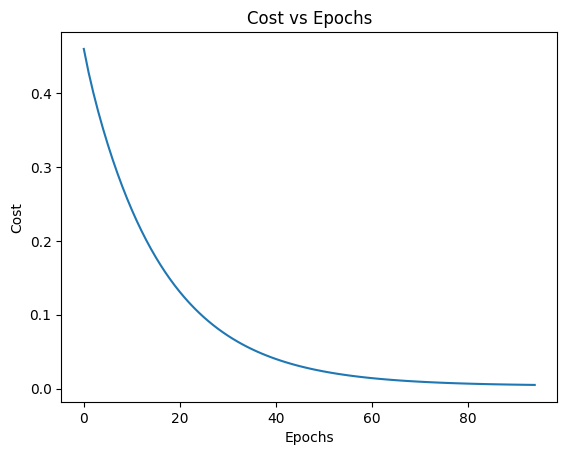

b,w found by gradient descent: 0.00, [ 5.37004472e-01  4.93472673e-01 -3.21017650e-01  1.86865522e-02
  1.16898342e-02  4.34379145e-04 -3.31427889e-01  6.21461825e-03
  1.55883838e-02  2.00517821e-02  5.70348659e-01  9.32258062e-04
 -3.28705690e-01  9.42723352e-03 -2.15363763e-03  6.90143147e-03]
prediction: -0.49, target: -0.49572918557655016
prediction: -0.52, target: -0.5246559134324996
prediction: -0.58, target: -0.4613621098210871
prediction: 0.01, target: 0.04923448406750146
prediction: -0.30, target: -0.28607676759614853
prediction: 0.04, target: -0.004505577674140302
prediction: -0.30, target: -0.33066109535886345
prediction: -0.78, target: -0.7655571755684842
prediction: 0.05, target: 0.09607453929904929
prediction: 0.02, target: 0.025880768984966156


In [494]:
# initialize parameters
initial_w = np.zeros(X_train.shape[1])
initial_b = 0.0
iterations = 95
alpha = 0.37

# run gradient descent 
w_final, b_final,J_history = gradient_descent(X_train, y_train, initial_w, initial_b, alpha, iterations)

print(f"b,w found by gradient descent: {b_final:.2f}, {w_final}")

# Predictions on training data
m, _ = X_train.shape
for i in range(10):  #just print a few
    prediction = (np.dot(X_train[i], w_final) + b_final)*sigma + mu
    print(f"prediction: {np.dot(X_train[i], w_final) + b_final:.2f}, target: {y_train[i]}")

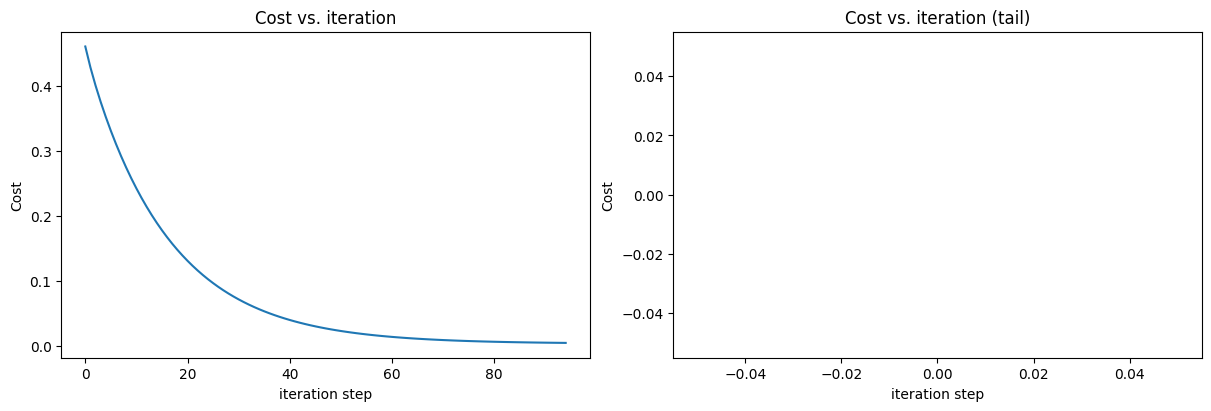

In [495]:
# plot cost versus iteration  
fig, (ax1, ax2) = plt.subplots(1, 2, constrained_layout=True, figsize=(12, 4))
ax1.plot(J_history)
ax2.plot(100 + np.arange(len(J_history[100:])), J_history[100:])
ax1.set_title("Cost vs. iteration");  ax2.set_title("Cost vs. iteration (tail)")
ax1.set_ylabel('Cost')             ;  ax2.set_ylabel('Cost') 
ax1.set_xlabel('iteration step')   ;  ax2.set_xlabel('iteration step') 
plt.show()

In [496]:
y_pred_test_norm = np.dot(X_test, w_final) + b_final
y_pred_test_actual = (y_pred_test_norm * sigma_y) + my
m = X_test.shape[0]
print(f"First {m} predicted close prices:{ y_pred_test_actual[:m]}")

First 173655 predicted close prices:[ 33.22749186 120.01427941  54.85735903 ...  94.88388231  -2.03746108
  20.73561747]


In [ ]:
r2_test = r_squared(y_test, y_pred_test_actual)
print(f"Final Testing R-squared: {r2_test:.4f}")

Final Testing R-squared: 0.9699
